# 모두몰 매출 TOP 리포트

모두몰 테이블 4개(`customers`, `orders`, `order_items`, `products`)를 JOIN해서 매출 관련 질문 5개에 SQL로 답하고, 결과에서 인사이트를 정리한 리포트다.

## 테이블 연결 구조

```
customers ──customer_id── orders ──order_id── order_items ──product_id── products
(name, country, grade)   (order_date, status, amount)   (quantity, unit_price)   (product_name, category, price)
```

## 과제 조건 체크

| 조건 | 사용한 질문 |
|---|---|
| INNER JOIN | Q1, Q4, Q5 |
| LEFT JOIN | Q2, Q3 |
| 서브쿼리 (WHERE절) | Q4 |
| 서브쿼리 (FROM절) | Q4, Q5 |
| JOIN + GROUP BY | Q1, Q2, Q4, Q5 |

## 오늘의 쿼리 패턴 적용

| 패턴 | SQL | 사용한 질문 |
|---|---|---|
| 두 테이블 합치기 | `FROM a JOIN b ON a.key = b.key` | Q1 |
| 짝 없는 행도 남기기 | `FROM a LEFT JOIN b ON ...` | Q2 |
| 짝 없는 행만 찾기 | `LEFT JOIN ... WHERE b.key IS NULL` | Q3 |
| 세로로 합치기 | `SELECT ... UNION DISTINCT SELECT ...` | Q4 |
| 조건에 다른 쿼리 결과 | `WHERE x > (SELECT ...)` | Q4 |
| 집계 결과를 다시 필터 | `FROM (SELECT ... GROUP BY ...) AS t WHERE ...` | Q5 |

## 0. 준비 — DuckDB에 모두몰 테이블 만들기

BigQuery에서 만든 테이블과 같은 데이터를 DuckDB로 노트북 안에 만든다. 쿼리는 BigQuery와 똑같이 `modumall.테이블` 형태로 쓴다.

In [1]:
# 처음 한 번만 실행한다 (설치 안 되어 있으면 주석을 해제한다)
# !pip install duckdb

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect()

def q(sql):
    """SQL을 실행하고 결과를 DataFrame으로 돌려준다."""
    return con.sql(sql).df()

In [2]:
setup_sql = """
CREATE SCHEMA IF NOT EXISTS modumall;

CREATE OR REPLACE TABLE modumall.customers (
  customer_id VARCHAR, name VARCHAR, country VARCHAR, signup_date DATE, grade VARCHAR
);
INSERT INTO modumall.customers VALUES
  ('C001', '김민준', 'Korea', '2023-01-05', 'Gold'),
  ('C002', '이서연', 'Korea', '2023-02-11', 'Silver'),
  ('C003', '박도윤', 'Japan', '2023-02-20', 'Bronze'),
  ('C004', '최지우', 'USA', '2023-03-03', 'Gold'),
  ('C005', '정하준', 'Korea', '2023-03-15', 'Silver'),
  ('C006', '강서윤', 'Korea', '2023-04-01', 'Bronze'),
  ('C007', '조은우', 'Japan', '2023-04-18', 'Silver'),
  ('C008', '윤지호', 'USA', '2023-05-09', 'Gold'),
  ('C009', '임하은', 'Korea', '2023-05-22', 'Bronze'),
  ('C010', '한예준', 'Korea', '2023-06-02', 'Silver'),
  ('C011', '오시우', NULL, '2023-06-19', 'Bronze'),
  ('C012', '신아린', 'Japan', '2023-07-07', 'Silver'),
  ('C013', '권준서', 'Korea', '2023-07-25', 'Gold'),
  ('C014', '황지안', 'USA', '2023-08-10', NULL),
  ('C015', '안수아', 'Korea', '2023-08-28', 'Bronze');

CREATE OR REPLACE TABLE modumall.products (
  product_id VARCHAR, product_name VARCHAR, category VARCHAR, price DECIMAL(12,2)
);
INSERT INTO modumall.products VALUES
  ('P01', '에어러너', 'Running', 89000),
  ('P02', '클래식 스니커즈', 'Sneakers', 65000),
  ('P03', '첼시 부츠', 'Boots', 145000),
  ('P04', '여름 샌들', 'Sandals', 38000),
  ('P05', '트레일 러너', 'Running', 119000),
  ('P06', '캔버스 스니커즈', 'Sneakers', 49000),
  ('P07', '워커 부츠', 'Boots', 175000),
  ('P08', '슬리퍼 샌들', 'Sandals', 25000),
  ('P09', '양말 세트', 'Accessory', 12000),
  ('P10', '운동화 끈', 'Accessory', 5000);

CREATE OR REPLACE TABLE modumall.orders (
  order_id VARCHAR, customer_id VARCHAR, order_date DATE, status VARCHAR, amount DECIMAL(12,2)
);
INSERT INTO modumall.orders VALUES
  ('O0001', 'C001', '2023-09-02', 'Paid', 125000),
  ('O0002', 'C002', '2023-09-05', 'Shipped', 89000),
  ('O0003', 'C001', '2023-09-11', 'Returned', 45000),
  ('O0004', 'C003', '2023-09-15', 'Paid', 230000),
  ('O0005', 'C004', '2023-09-20', 'Cancelled', NULL),
  ('O0006', 'C005', '2023-09-25', 'Shipped', 67000),
  ('O0007', 'C002', '2023-10-01', 'Paid', 158000),
  ('O0008', 'C006', '2023-10-04', 'Placed', 32000),
  ('O0009', 'C007', '2023-10-12', 'Shipped', 410000),
  ('O0010', 'C008', '2023-10-19', 'Paid', 99000),
  ('O0011', 'C001', '2023-10-23', 'Paid', 76000),
  ('O0012', 'C009', '2023-10-28', 'Cancelled', NULL),
  ('O0013', 'C010', '2023-11-02', 'Shipped', 142000),
  ('O0014', 'C004', '2023-11-08', 'Paid', 88000),
  ('O0015', 'C011', '2023-11-13', 'Placed', 53000),
  ('O0016', 'C012', '2023-11-19', 'Shipped', 175000),
  ('O0017', 'C002', '2023-11-24', 'Returned', 61000),
  ('O0018', 'C013', '2023-11-29', 'Paid', 320000),
  ('O0019', 'C005', '2023-12-03', 'Paid', 47000),
  ('O0020', 'C008', '2023-12-09', 'Shipped', 215000),
  ('O0021', 'C014', '2023-12-14', 'Placed', 38000),
  ('O0022', 'C001', '2023-12-20', 'Paid', 134000),
  ('O0023', 'C015', '2023-12-25', 'Shipped', 92000),
  ('O0024', 'C007', '2024-01-03', 'Paid', 268000),
  ('O0025', 'C010', '2024-01-09', 'Cancelled', NULL),
  ('O0026', 'C003', '2024-01-15', 'Paid', 119000),
  ('O0027', 'C013', '2024-01-22', 'Shipped', 405000),
  ('O0028', 'C006', '2024-01-28', 'Paid', 58000),
  ('O0029', 'C004', '2024-02-04', 'Returned', 73000),
  ('O0030', 'C012', '2024-02-11', 'Paid', 187000);

CREATE OR REPLACE TABLE modumall.order_items (
  order_id VARCHAR, product_id VARCHAR, quantity BIGINT, unit_price DECIMAL(12,2)
);
INSERT INTO modumall.order_items VALUES
  ('O0001', 'P01', 1, 125000), ('O0002', 'P02', 2, 44500), ('O0003', 'P03', 1, 45000),
  ('O0004', 'P04', 2, 115000), ('O0006', 'P05', 1, 67000), ('O0007', 'P06', 2, 79000),
  ('O0008', 'P07', 1, 32000), ('O0009', 'P08', 2, 205000), ('O0010', 'P09', 1, 99000),
  ('O0011', 'P01', 2, 38000), ('O0013', 'P02', 1, 142000), ('O0014', 'P03', 2, 44000),
  ('O0015', 'P04', 1, 53000), ('O0016', 'P05', 2, 87500), ('O0017', 'P06', 1, 61000),
  ('O0018', 'P07', 2, 160000), ('O0019', 'P08', 1, 47000), ('O0020', 'P09', 2, 107500),
  ('O0021', 'P01', 1, 38000), ('O0022', 'P02', 2, 67000), ('O0023', 'P03', 1, 92000),
  ('O0024', 'P04', 2, 134000), ('O0026', 'P05', 1, 119000), ('O0027', 'P06', 2, 202500),
  ('O0028', 'P07', 1, 58000), ('O0029', 'P08', 2, 36500), ('O0030', 'P09', 1, 187000);
"""

con.execute(setup_sql)
print("테이블 생성 완료")

테이블 생성 완료


In [3]:
# 테이블별 행 수를 확인한다.
q("""
SELECT 'customers' AS table_name, COUNT(*) AS row_count FROM modumall.customers
UNION ALL SELECT 'orders', COUNT(*) FROM modumall.orders
UNION ALL SELECT 'order_items', COUNT(*) FROM modumall.order_items
UNION ALL SELECT 'products', COUNT(*) FROM modumall.products
""")

,table_name,row_count
0,customers,15
1,orders,30
2,order_items,27
3,products,10


---
## Q1. 고객 등급별 매출은?

**패턴:** 두 테이블 합치기 (INNER JOIN) + GROUP BY

주문(`orders`)에는 금액이, 고객(`customers`)에는 등급이 있으므로 고객번호로 연결한다. 주문이 있는 고객만 보면 되므로 INNER JOIN을 사용한다.

In [4]:
q1 = q("""
SELECT
  c.grade,
  COUNT(o.order_id) AS order_count,
  SUM(o.amount) AS total_revenue,
  ROUND(AVG(o.amount), 0) AS avg_order_amount
FROM modumall.orders AS o
INNER JOIN modumall.customers AS c
  ON o.customer_id = c.customer_id
WHERE o.amount IS NOT NULL
GROUP BY c.grade
ORDER BY total_revenue DESC
""")
q1

,grade,order_count,total_revenue,avg_order_amount
0,Silver,10,1604000.0,160400.0
1,Gold,10,1580000.0,158000.0
2,Bronze,6,584000.0,97333.0
3,NaN,1,38000.0,38000.0


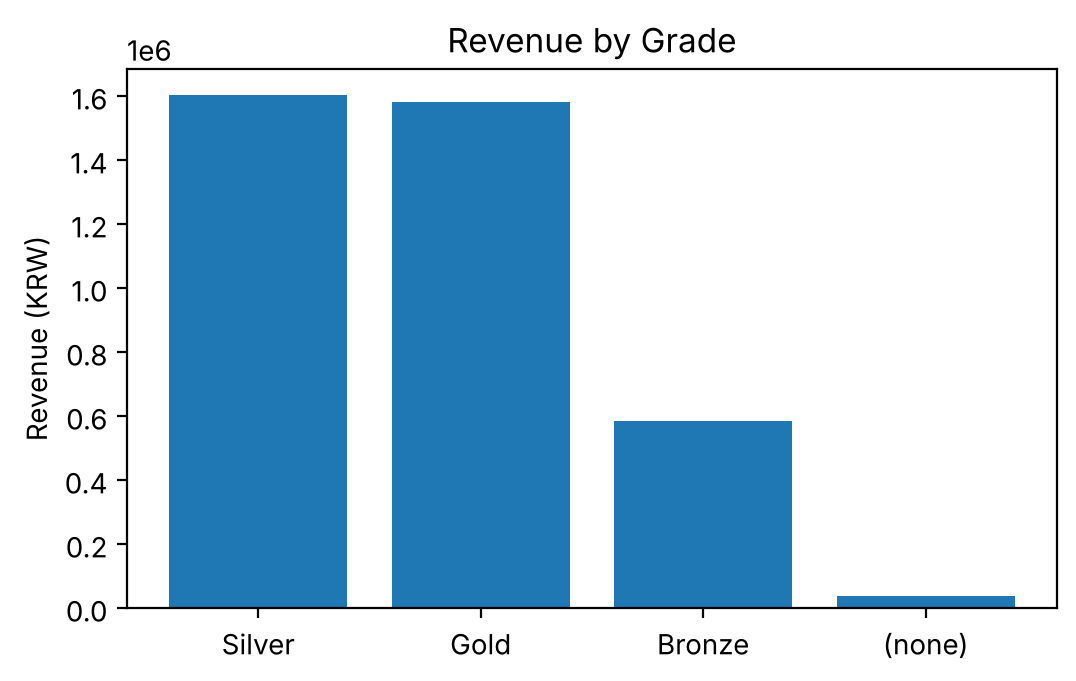

In [5]:
plot_df = q1.copy()
plot_df['grade'] = plot_df['grade'].fillna('(none)')
plt.figure(figsize=(6, 3.5))
plt.bar(plot_df['grade'], plot_df['total_revenue'])
plt.title('Revenue by Grade')
plt.ylabel('Revenue (KRW)')
plt.show()

**인사이트:** Silver(160.4만 원)와 Gold(158만 원)의 매출이 거의 같고, Bronze는 주문 1건 평균이 약 9.7만 원으로 Silver·Gold(약 16만 원)의 60% 수준이라, 상위 등급 유지만큼 Bronze → Silver 승급 유도가 매출을 늘릴 여지가 크다.

> 참고: 등급이 비어 있는(NULL) 고객(C014) 주문 1건이 따로 묶여 나온다. 등급 데이터 누락을 보완할 필요가 있다.

---
## Q2. 상품별 판매 수량과 매출은? (안 팔린 상품 포함)

**패턴:** 짝 없는 행도 남기기 (LEFT JOIN) + GROUP BY

`products`를 왼쪽에 두고 LEFT JOIN해서 한 번도 팔리지 않은 상품도 목록에 남긴다. 안 팔린 상품은 합계가 NULL이 되므로 `COALESCE`로 0으로 바꾼다.

In [6]:
q2 = q("""
SELECT
  p.product_name,
  p.category,
  COALESCE(SUM(oi.quantity), 0) AS total_quantity,
  COALESCE(SUM(oi.quantity * oi.unit_price), 0) AS revenue
FROM modumall.products AS p
LEFT JOIN modumall.order_items AS oi
  ON p.product_id = oi.product_id
GROUP BY p.product_name, p.category
ORDER BY total_quantity DESC, revenue DESC
""")
q2

,product_name,category,total_quantity,revenue
0,캔버스 스니커즈,Sneakers,5.0,624000.0
1,여름 샌들,Sandals,5.0,551000.0
2,슬리퍼 샌들,Sandals,5.0,530000.0
3,클래식 스니커즈,Sneakers,5.0,365000.0
4,양말 세트,Accessory,4.0,501000.0
5,워커 부츠,Boots,4.0,410000.0
6,트레일 러너,Running,4.0,361000.0
7,에어러너,Running,4.0,239000.0
8,첼시 부츠,Boots,4.0,225000.0
9,운동화 끈,Accessory,0.0,0.0


**인사이트:** 판매 수량 상위 4개(각 5개)가 모두 Sneakers·Sandals 상품이고, 매출 1위는 캔버스 스니커즈(62.4만 원)다. 반면 운동화 끈은 판매가 0이라 전체 상품 10개 중 유일하게 안 팔렸다.

---
## Q3. 한 번도 팔리지 않은 상품은?

**패턴:** 짝 없는 행만 찾기 (LEFT JOIN ... WHERE ... IS NULL)

LEFT JOIN 후 `order_items` 쪽이 NULL인 행 = 주문 상세에 한 번도 등장하지 않은 상품이다.

In [7]:
q3 = q("""
SELECT
  p.product_id,
  p.product_name,
  p.category,
  p.price
FROM modumall.products AS p
LEFT JOIN modumall.order_items AS oi
  ON p.product_id = oi.product_id
WHERE oi.product_id IS NULL
""")
q3

,product_id,product_name,category,price
0,P10,운동화 끈,Accessory,5000.0


**인사이트:** 미판매 상품은 운동화 끈(5,000원, Accessory) 1개뿐이다. 같은 Accessory인 양말 세트는 팔렸으므로, 운동화 끈은 단독 판매보다 스니커즈·러닝화 구매 시 함께 추천하는 묶음 상품으로 노출하는 것을 검토할 만하다.

---
## Q4. '주의 주문'(평균보다 큰 주문 또는 반품 주문)은 어느 등급 고객에게 많은가?

**패턴:** 세로로 합치기 (UNION DISTINCT) + 조건에 다른 쿼리 결과 (WHERE절 서브쿼리) + FROM절 서브쿼리 + JOIN + GROUP BY

1. WHERE절 서브쿼리로 전체 평균 금액을 구해 평균보다 큰 주문을 뽑는다.
2. 반품 주문과 `UNION DISTINCT`로 합쳐 중복 없는 '주의 주문' 목록을 만든다. (BigQuery는 `UNION`만 쓰면 에러가 나므로 `DISTINCT`/`ALL`을 반드시 붙인다.)
3. 그 목록을 FROM절 서브쿼리로 쓰고, 주문·고객과 JOIN해서 등급별로 집계한다.

In [8]:
# 기준이 되는 전체 평균 주문 금액을 구한다.
q("SELECT ROUND(AVG(amount), 0) AS avg_amount FROM modumall.orders")

,avg_amount
0,140963.0


In [9]:
q4 = q("""
SELECT
  c.grade,
  COUNT(*) AS watch_order_count
FROM (
  SELECT order_id
  FROM modumall.orders
  WHERE amount > (SELECT AVG(amount) FROM modumall.orders)

  UNION DISTINCT

  SELECT order_id
  FROM modumall.orders
  WHERE status = 'Returned'
) AS w
INNER JOIN modumall.orders AS o
  ON w.order_id = o.order_id
INNER JOIN modumall.customers AS c
  ON o.customer_id = c.customer_id
GROUP BY c.grade
ORDER BY watch_order_count DESC
""")
q4

,grade,watch_order_count
0,Silver,7
1,Gold,5
2,Bronze,1


**인사이트:** 주의 주문 13건 중 Silver가 7건으로 가장 많고 Gold가 5건이다. 특히 반품 3건 중 2건이 Gold 고객 주문이라, 최상위 등급의 반품 사유를 따로 확인해 볼 필요가 있다.

---
## Q5. 총 구매액 20만 원 이상 고객(VIP)은 어느 나라에 많은가?

**패턴:** 집계 결과를 다시 필터 (FROM절 서브쿼리) + JOIN + GROUP BY

FROM절 서브쿼리에서 고객별 총 구매액을 먼저 계산하고, 바깥에서 20만 원 이상 고객만 남긴 뒤 나라별로 집계한다.

In [10]:
q5 = q("""
SELECT
  c.country,
  COUNT(*) AS vip_count,
  SUM(t.total_amount) AS vip_revenue
FROM (
  SELECT customer_id, SUM(amount) AS total_amount
  FROM modumall.orders
  WHERE amount IS NOT NULL
  GROUP BY customer_id
) AS t
INNER JOIN modumall.customers AS c
  ON t.customer_id = c.customer_id
WHERE t.total_amount >= 200000
GROUP BY c.country
ORDER BY vip_count DESC
""")
q5

,country,vip_count,vip_revenue
0,Korea,3,1413000.0
1,Japan,3,1389000.0
2,USA,1,314000.0


In [11]:
# 비교용으로 나라별 전체 고객 수를 센다.
q("""
SELECT country, COUNT(*) AS customer_count
FROM modumall.customers
GROUP BY country
ORDER BY customer_count DESC
""")

,country,customer_count
0,Korea,8
1,USA,3
2,Japan,3
3,NaN,1


**인사이트:** VIP 수는 Korea와 Japan이 3명으로 같지만, Japan은 고객 3명이 전부 VIP(100%)인 반면 Korea는 8명 중 3명(약 38%)이라, 일본 고객은 수는 적어도 1인당 구매력이 높은 핵심 시장이다.

---
## 정리

| 질문 | 인사이트 |
|---|---|
| Q1 등급별 매출 | Silver·Gold 매출이 비슷하고 Bronze 객단가가 낮아 승급 유도 여지가 크다. |
| Q2 상품별 판매 | Sneakers·Sandals가 수량 상위이고, 매출 1위는 캔버스 스니커즈다. |
| Q3 미판매 상품 | 운동화 끈 1개만 안 팔려서 묶음 추천을 검토할 만하다. |
| Q4 주의 주문 | Silver가 가장 많고, 반품 3건 중 2건이 Gold다. |
| Q5 국가별 VIP | Japan은 고객 전원이 VIP인 고구매력 시장이다. |

- `JOIN`은 옆으로(열), `UNION`은 세로로(행) 데이터를 합친다
- 짝이 없는 데이터까지 봐야 하는 질문(안 팔린 상품)에는 LEFT JOIN, 양쪽에 다 있는 데이터만 보면 되는 질문에는 INNER JOIN이 맞다